# Dog Breed Classification, transfer learning warmup

The full version of this task is Stanford Dogs (120 breeds, about 750MB). To keep it CPU-sized I use real photos from the Oxford-IIIT Pet dataset (Parkhi et al., 2012, CC BY-SA 4.0), loaded from the `timm/oxford-iiit-pet` parquet on Hugging Face. Pets has 25 dog breeds; I take 6 of them (about 100 training photos each, roughly 600 images) and fine-tune a new head on a frozen ImageNet ResNet18.

The parquet is stored one breed per row group, so I only download the six row groups I need (about 60MB) instead of the whole 378MB file.

In [1]:
import io
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem
from PIL import Image
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

torch.set_num_threads(2)
np.random.seed(3); torch.manual_seed(3)
device = torch.device('cpu')

In [2]:
# Oxford-IIIT Pet train split, one breed per parquet row group
BREEDS = ['beagle', 'pug', 'samoyed', 'shiba_inu', 'pomeranian', 'saint_bernard']
fs = HfFileSystem()
pf = pq.ParquetFile(fs.open("datasets/timm/oxford-iiit-pet/data/train-00000-of-00001.parquet"))
ALL_NAMES = ["abyssinian", "american_bulldog", "american_pit_bull_terrier", "basset_hound", "beagle", "bengal",
             "birman", "bombay", "boxer", "british_shorthair", "chihuahua", "egyptian_mau", "english_cocker_spaniel",
             "english_setter", "german_shorthaired", "great_pyrenees", "havanese", "japanese_chin", "keeshond",
             "leonberger", "maine_coon", "miniature_pinscher", "newfoundland", "persian", "pomeranian", "pug",
             "ragdoll", "russian_blue", "saint_bernard", "samoyed", "scottish_terrier", "shiba_inu", "siamese",
             "sphynx", "staffordshire_bull_terrier", "wheaten_terrier", "yorkshire_terrier"]
wanted = {ALL_NAMES.index(b): i for i, b in enumerate(BREEDS)}

images, y = [], []
for rg in range(pf.metadata.num_row_groups):
    labels = pf.read_row_group(rg, columns=["label"]).column("label").to_pylist()
    if not set(labels) & set(wanted):
        continue
    t = pf.read_row_group(rg, columns=["image", "label"]).to_pylist()
    for row in t:
        if row["label"] in wanted:
            images.append(Image.open(io.BytesIO(row["image"]["bytes"])).convert("RGB"))
            y.append(wanted[row["label"]])
y = np.array(y)
print('real photos:', len(images), '| per breed:', np.bincount(y))

real photos: 600 | per breed: [100 100 100 100 100 100]


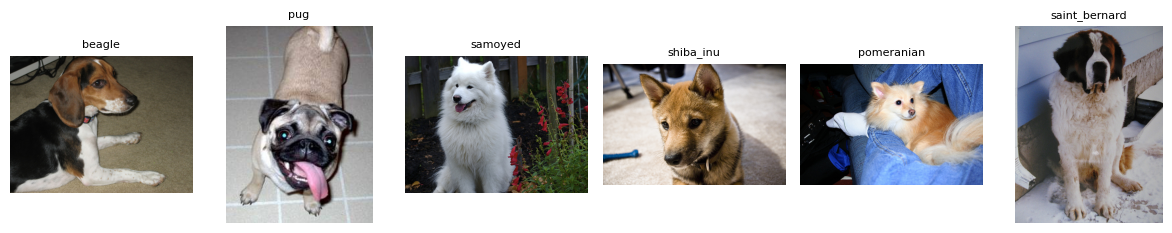

In [3]:
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, c in zip(axes, range(6)):
    ax.imshow(images[int(np.where(y == c)[0][0])])
    ax.set_title(BREEDS[c], fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

## Transfer learning setup

ResNet18 pretrained on ImageNet, expects 224x224 + the standard normalization. I resize each photo to 256 on the short side, center-crop 224, and apply ImageNet stats. The backbone stays frozen, so I run it once to get 512-d features and then train only the new final FC layer on top.

In [4]:
imnet_mean = [0.485, 0.456, 0.406]
imnet_std  = [0.229, 0.224, 0.225]
to_input = transforms.Compose([
    transforms.Resize(256, antialias=True),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(imnet_mean, imnet_std),
])

backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in backbone.parameters():
    p.requires_grad = False
backbone.fc = nn.Linear(backbone.fc.in_features, len(BREEDS))
backbone = backbone.to(device)
print('trainable params:', sum(p.numel() for p in backbone.parameters() if p.requires_grad))

# frozen backbone -> compute the 512-d pooled features once
feature_extractor = nn.Sequential(*list(backbone.children())[:-1]).eval()
feats = []
with torch.no_grad():
    for i in range(0, len(images), 32):
        xb = torch.stack([to_input(im) for im in images[i:i + 32]])
        feats.append(feature_extractor(xb).flatten(1))
feats = torch.cat(feats)
print('features:', feats.shape)

trainable params: 3078


features: torch.Size([600, 512])


In [5]:
idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=3)
Ftr, Fte = feats[idx_tr], feats[idx_te]
ytr_t, yte = torch.tensor(y[idx_tr]), y[idx_te]
print('train:', len(idx_tr), '| test:', len(idx_te))

head = backbone.fc
opt = torch.optim.Adam(head.parameters(), lr=1e-3)
batch = 32
for ep in range(15):
    head.train(); perm = torch.randperm(len(Ftr)); losses = []
    for i in range(0, len(perm), batch):
        idx = perm[i:i + batch]
        opt.zero_grad()
        loss = F.cross_entropy(head(Ftr[idx]), ytr_t[idx])
        loss.backward(); opt.step()
        losses.append(loss.item())
    if ep % 3 == 2:
        print(f'epoch {ep}  mean_loss={np.mean(losses):.4f}')

train: 450 | test: 150


epoch 2  mean_loss=0.2116
epoch 5  mean_loss=0.0885
epoch 8  mean_loss=0.0854
epoch 11  mean_loss=0.0430
epoch 14  mean_loss=0.0351


In [6]:
head.eval()
with torch.no_grad():
    preds = head(Fte).argmax(1).numpy()
print(f'test acc on {len(yte)} held-out photos: {accuracy_score(yte, preds):.3f}')
print(classification_report(yte, preds, target_names=BREEDS, digits=3))

test acc on 150 held-out photos: 0.987
               precision    recall  f1-score   support

       beagle      0.962     1.000     0.980        25
          pug      1.000     1.000     1.000        25
      samoyed      0.962     1.000     0.980        25
    shiba_inu      1.000     1.000     1.000        25
   pomeranian      1.000     0.960     0.980        25
saint_bernard      1.000     0.960     0.980        25

     accuracy                          0.987       150
    macro avg      0.987     0.987     0.987       150
 weighted avg      0.987     0.987     0.987       150



## Takeaways

On 150 held-out real photos (25 per breed), the new linear head on frozen ResNet18 features gets 98.7% accuracy, with only two mistakes. That is high, but it isn't a fluke of the setup: beagle, pug, Samoyed, Pomeranian and Saint Bernard are all classes in ImageNet itself, so the pretrained features already separate them well, and these six breeds look quite different from each other. Only 3,078 parameters are trained.

The harder and more useful test is the full problem: all 25 Pets dog breeds or the 120 Stanford Dogs breeds, where look-alike breeds (several terriers, for example) sit next to each other. For that I'd (1) keep the head training for a few epochs, then unfreeze `layer4` for another epoch at 1e-4, (2) add light augmentation (horizontal flip + color jitter), and (3) report per-breed confusion, since the errors will cluster in the look-alike groups. That needs more compute than this CPU budget.